In [1]:
import random
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu130
Device: cuda
GPU: NVIDIA L4


In [2]:
from google.colab import drive
import os

drive.mount('/content/drive')

folder = "/content/drive/MyDrive/SNN_XAI_PROJECT"

print("Project folder exists:", os.path.exists(folder))
print("Files:", os.listdir(folder) if os.path.exists(folder) else "Not found")


Mounted at /content/drive
Project folder exists: True
Files: ['MILK10k_Training_GroundTruth.csv', 'MILK10k_Training_Input.zip', 'MILK10k_Training_Supplement.csv', 'MILK10k_Training_Metadata.csv', 'images', 'checkpoints_v5']


In [3]:

import pandas as pd
import os

# Read classification labels
csv_path = os.path.join(folder, "MILK10k_Training_GroundTruth.csv")
df = pd.read_csv(csv_path)

print("CSV Shape:", df.shape)

display(df.head(10))

# Inspect image folder
images_path = os.path.join(folder, "images")

print("\nImage Folder Contents:")
print(os.listdir(images_path)[:15])


CSV Shape: (5240, 12)


,lesion_id,AKIEC,BCC,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC
0,IL_0000652,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,IL_0003176,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,IL_0004688,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,IL_0005081,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,IL_0006177,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,IL_0006407,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,IL_0008891,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
7,IL_0008969,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,IL_0009339,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,IL_0011263,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Image Folder Contents:
['MILK10k_Training_Input']


In [4]:
import os

image_root = os.path.join(
    folder, "images", "MILK10k_Training_Input"
)

print("Folder exists:", os.path.exists(image_root))

if os.path.exists(image_root):
    items = os.listdir(image_root)
    print("Total entries:", len(items))
    print("First 15 entries:", items[:15])



Folder exists: True
Total entries: 5242
First 15 entries: ['IL_8073547', 'IL_8074133', 'IL_8075238', 'IL_8077047', 'IL_8079402', 'IL_8083531', 'IL_8089688', 'IL_8091560', 'IL_8093153', 'IL_8095126', 'IL_8098270', 'IL_8099275', 'IL_8102879', 'IL_8106703', 'IL_8107077']


In [5]:

# Select the first lesion folder
lesion_folder = os.path.join(image_root, "IL_8073547")

print("Lesion ID:", os.path.basename(lesion_folder))
print("Files inside:")

for filename in os.listdir(lesion_folder):
    print(filename)


Lesion ID: IL_8073547
Files inside:
ISIC_2655730.jpg
ISIC_1348618.jpg


Filename: ISIC_1348618.jpg
Original size (Width, Height): (600, 450)
Image mode: RGB
Filename: ISIC_2655730.jpg
Original size (Width, Height): (600, 450)
Image mode: RGB


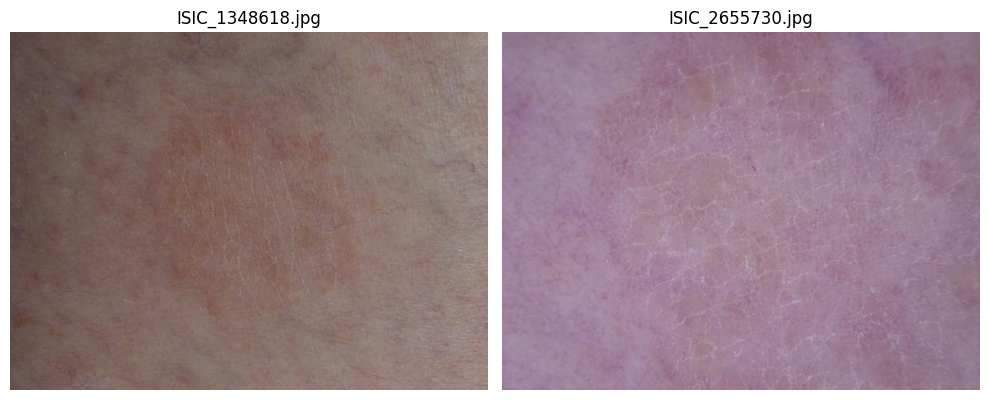

In [6]:

from PIL import Image
import matplotlib.pyplot as plt

files = sorted(os.listdir(lesion_folder))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for i, filename in enumerate(files):
    path = os.path.join(lesion_folder, filename)
    img = Image.open(path)

    print("Filename:", filename)
    print("Original size (Width, Height):", img.size)
    print("Image mode:", img.mode)

    axes[i].imshow(img)
    axes[i].set_title(filename)
    axes[i].axis("off")

plt.tight_layout()
plt.show()


In [7]:

metadata = pd.read_csv(
    os.path.join(folder, "MILK10k_Training_Metadata.csv")
)

supplement = pd.read_csv(
    os.path.join(folder, "MILK10k_Training_Supplement.csv")
)

print("\nMetadata first 3 rows:")
display(metadata.head(3))


print("\nSupplement first 3 rows:")
display(supplement.head(3))



Metadata first 3 rows:


,lesion_id,image_type,isic_id,attribution,copyright_license,image_manipulation,age_approx,sex,skin_tone_class,site,MONET_ulceration_crust,MONET_hair,MONET_vasculature_vessels,MONET_erythema,MONET_pigmented,MONET_gel_water_drop_fluid_dermoscopy_liquid,MONET_skin_markings_pen_ink_purple_pen
0,IL_0000652,clinical: close-up,ISIC_8149219,MILK study team,CC-BY-NC,altered,70.0,male,1,head_neck_face,0.166749,0.163601,0.002284,0.124315,0.719495,0.220399,0.237601
1,IL_0000652,dermoscopic,ISIC_4671410,MILK study team,CC-BY-NC,instrument only,70.0,male,1,head_neck_face,0.659859,0.156478,0.016397,0.032357,0.847014,0.138121,0.148776
2,IL_0003176,clinical: close-up,ISIC_3904045,MILK study team,CC-BY-NC,instrument only,45.0,female,5,head_neck_face,0.348609,0.614718,0.013415,0.447485,0.061977,0.296341,0.058006



Supplement first 3 rows:


,isic_id,diagnosis_full,diagnosis_confirm_type,invasion_thickness_interval
0,ISIC_0051817,"Squamous cell carcinoma, Invasive",histopathology,NaN
1,ISIC_0073863,"Nevus, Reed",histopathology,NaN
2,ISIC_0075884,"Nevus, Acral",histopathology,NaN


In [8]:

# Get all lesion IDs from the GroundTruth CSV
csv_ids = set(df["lesion_id"])

# Get all lesion folder names
folder_ids = {
    name for name in os.listdir(image_root)
    if os.path.isdir(os.path.join(image_root, name))
}

# Compare both
missing_folders = csv_ids - folder_ids
extra_folders = folder_ids - csv_ids

print("Labeled lesions:", len(csv_ids))
print("Lesion folders:", len(folder_ids))
print("Missing folders:", len(missing_folders))
print("Extra folders:", len(extra_folders))

print("\nMissing IDs:", sorted(missing_folders)[:10])
print("Extra IDs:", sorted(extra_folders)[:10])

# Check metadata image types for every labeled lesion
pair_counts = (
    metadata[metadata["lesion_id"].isin(csv_ids)]
    .groupby(["lesion_id", "image_type"])
    .size()
    .unstack(fill_value=0)
)

valid_pairs = (
    (pair_counts.get("dermoscopic", 0) == 1)
    & (pair_counts.get("clinical: close-up", 0) == 1)
)

print("\nValid metadata pairs:", valid_pairs.sum())
print("Invalid metadata pairs:", (~valid_pairs).sum())
print("Labeled lesions absent from metadata:",
      len(csv_ids - set(pair_counts.index)))


Labeled lesions: 5240
Lesion folders: 5241
Missing folders: 0
Extra folders: 1

Missing IDs: []
Extra IDs: ['licenses']

Valid metadata pairs: 5240
Invalid metadata pairs: 0
Labeled lesions absent from metadata: 0


Processed tensor shape: torch.Size([3, 192, 192])
Pixel range: 0.0 0.7019608020782471


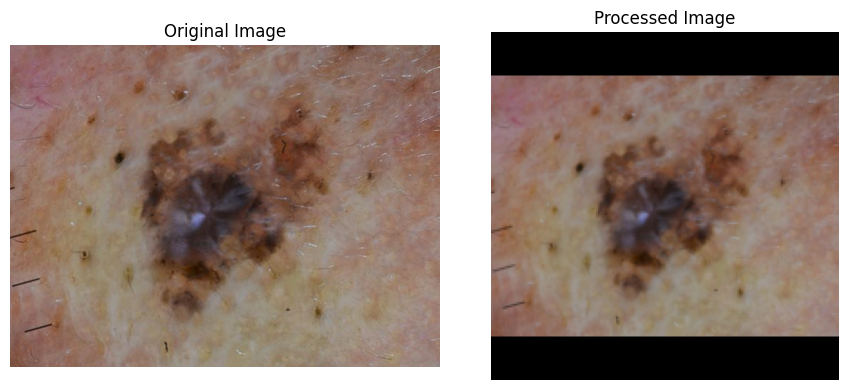

In [9]:
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import os

transform=transforms.Compose([
    transforms.Resize((144,192)),     #144 height which will become 192 after adding 24 padding from top and bottom and 192 width
    transforms.Pad((0,24,0,24)),
    transforms.ToTensor()
])
def load_image(lesion_id,image_id):
    path=os.path.join(image_root,lesion_id,image_id+".jpg")
    image=Image.open(path).convert("RGB")
    return transform(image)

processed=load_image("IL_0000652","ISIC_4671410")
original=Image.open(os.path.join(image_root,"IL_0000652","ISIC_4671410.jpg")).convert("RGB")
print("Processed tensor shape:",processed.shape)   # channel , height and width
print("Pixel range:",processed.min().item(),processed.max().item())
fig,axes=plt.subplots(1,2,figsize=(9,4))
axes[0].imshow(original)
axes[0].set_title("Original Image")
axes[0].axis("off")
axes[1].imshow(processed.permute(1,2,0))
axes[1].set_title("Processed Image")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [10]:
#image loader, taake training ke waqt har lesion ki correct images aur label model ko mil sakein.
import torch
from torch.utils.data import Dataset

class MILK10kDataset(Dataset):
    def __init__(self,df,metadata,image_root,transform):
        self.df=df.reset_index(drop=True)
        self.image_root=image_root
        self.transform=transform
        self.class_names=["AKIEC","BCC","BEN_OTH","BKL","DF","INF","MAL_OTH","MEL","NV","SCCKA","VASC"]
        self.image_pairs={}
        for _,row in metadata.iterrows():
            lesion_id=row["lesion_id"]
            image_type=str(row["image_type"]).lower()
            if lesion_id not in self.image_pairs:
                self.image_pairs[lesion_id]={}
            if "dermoscopic" in image_type:
                self.image_pairs[lesion_id]["dermoscopic"]=row["isic_id"]
            elif "close-up" in image_type:
                self.image_pairs[lesion_id]["closeup"]=row["isic_id"]

    def __len__(self):
        return len(self.df)

    def __getitem__(self,index):
        row=self.df.iloc[index]
        lesion_id=row["lesion_id"]
        label=int(row[self.class_names].to_numpy().argmax())
        pair=self.image_pairs[lesion_id]
        dermoscopic=load_image(lesion_id,pair["dermoscopic"])
        closeup=load_image(lesion_id,pair["closeup"])
        return dermoscopic,closeup,torch.tensor(label,dtype=torch.long)

In [12]:
from sklearn.model_selection import train_test_split
import numpy as np
dataset = MILK10kDataset(df, metadata, image_root, transform)
class_names=dataset.class_names
labels=df[class_names].to_numpy().argmax(axis=1)
indices=np.arange(len(df))

train_idx,temp_idx=train_test_split(indices,test_size=0.30,random_state=42,stratify=labels)
val_idx,test_idx=train_test_split(temp_idx,test_size=0.50,random_state=42,stratify=labels[temp_idx])

print("Training lesions:",len(train_idx))
print("Validation lesions:",len(val_idx))
print("Testing lesions:",len(test_idx))
print("Total:",len(train_idx)+len(val_idx)+len(test_idx))

Training lesions: 3668
Validation lesions: 786
Testing lesions: 786
Total: 5240


In [28]:
# from torch.utils.data import DataLoader,Subset

# train_dataset=Subset(dataset,train_idx)
# val_dataset=Subset(dataset,val_idx)
# test_dataset=Subset(dataset,test_idx)

# train_loader=DataLoader(train_dataset,batch_size=4,shuffle=True,num_workers=0)
# val_loader=DataLoader(val_dataset,batch_size=4,shuffle=False,num_workers=0)
# test_loader=DataLoader(test_dataset,batch_size=4,shuffle=False,num_workers=0)

# print("Training batches:",len(train_loader))
# print("Validation batches:",len(val_loader))
# print("Testing batches:",len(test_loader))

import numpy as np
import torch
from torch.utils.data import DataLoader,Subset,WeightedRandomSampler

train_dataset=Subset(dataset,train_idx)
val_dataset=Subset(dataset,val_idx)
test_dataset=Subset(dataset,test_idx)

train_labels=df[class_names].to_numpy().argmax(axis=1)[train_idx]

class_counts=np.bincount(train_labels,minlength=len(class_names))
class_weights=1.0/np.maximum(class_counts,1)
sample_weights=class_weights[train_labels]

weighted_sampler=WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(train_idx),
    replacement=True
)

train_loader=DataLoader(train_dataset,batch_size=1,sampler=weighted_sampler,num_workers=0)
val_loader=DataLoader(val_dataset,batch_size=1,shuffle=False,num_workers=0)
test_loader=DataLoader(test_dataset,batch_size=1,shuffle=False,num_workers=0)

print("Class counts:",class_counts)
print("Training batches:",len(train_loader))
print("Validation batches:",len(val_loader))
print("Testing batches:",len(test_loader))

Class counts: [ 212 1765   31  381   37   35    6  315  522  331   33]
Training batches: 3668
Validation batches: 786
Testing batches: 786


In [29]:
dermoscopic,closeup,labels=next(iter(train_loader))

print("Dermoscopic batch:",dermoscopic.shape)
print("Close-up batch:",closeup.shape)
print("Labels:",labels)
print("Labels shape:",labels.shape)

Dermoscopic batch: torch.Size([1, 3, 192, 192])
Close-up batch: torch.Size([1, 3, 192, 192])
Labels: tensor([8])
Labels shape: torch.Size([1])


In [30]:
import importlib.util

if importlib.util.find_spec("snntorch") is None:
    %pip install snntorch

print("snntorch imported successfully")

snntorch imported successfully


In [31]:
import torch.nn as nn
import snntorch as snn
from snntorch import surrogate

class SpikingConvBlock(nn.Module):
    def __init__(self,in_channels,out_channels):
        super().__init__()
        self.conv=nn.Conv2d(in_channels,out_channels,kernel_size=3,padding=1)
        self.bn=nn.BatchNorm2d(out_channels)
        self.if_neuron=snn.Leaky(beta=1.0,spike_grad=surrogate.fast_sigmoid(slope=25))

    def forward(self,x,mem):
        current=self.bn(self.conv(x))
        spikes,mem=self.if_neuron(current,mem)
        return spikes,mem

In [32]:
class SNNBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.blocks=nn.ModuleList()
        channels=[3,64,128,256,512,512]
        for i in range(5):
            block=nn.ModuleList([
                SpikingConvBlock(channels[i],channels[i+1]),
                SpikingConvBlock(channels[i+1],channels[i+1])
            ])
            self.blocks.append(block)
        self.pool=nn.AvgPool2d(kernel_size=2)
        self.global_pool=nn.AdaptiveAvgPool2d(1)
    def forward(self,x,mem_states=None):
        if mem_states is None:
            mem_states=[(None,None) for _ in range(5)]
        new_mem_states=[]
        for i,block in enumerate(self.blocks):
            mem1,mem2=mem_states[i]
            x,mem1=block[0](x,mem1)
            x,mem2=block[1](x,mem2)
            x=self.pool(x)
            new_mem_states.append((mem1,mem2))
        x=self.global_pool(x)
        x=torch.flatten(x,1)
        return x,new_mem_states

In [33]:
from snntorch import utils
class DualBranchSNN(nn.Module):
    def __init__(self,num_classes=11,num_steps=30):
        super().__init__()
        self.num_steps=num_steps
        self.derm_branch=SNNBranch()   #512 features
        self.close_branch=SNNBranch()  #512 features
        self.fc1=nn.Linear(1024,256)   #1024 features(concatenation 512+512)
        self.fc1_if=snn.Leaky(beta=1.0,spike_grad=surrogate.fast_sigmoid(slope=25))
        self.fc2=nn.Linear(256,num_classes)
    def forward(self,derm,close):
        utils.reset(self)
        derm_mem=None
        close_mem=None
        fc_mem=None
        output_sum=0
        for t in range(self.num_steps):
            derm_spikes=torch.bernoulli(derm)
            close_spikes=torch.bernoulli(close)
            derm_features,derm_mem=self.derm_branch(derm_spikes,derm_mem)
            close_features,close_mem=self.close_branch(close_spikes,close_mem)
            combined=torch.cat((derm_features,close_features),dim=1)
            hidden=self.fc1(combined)
            hidden_spikes,fc_mem=self.fc1_if(hidden,fc_mem)
            output=self.fc2(hidden_spikes)
            output_sum=output_sum+output
        return output_sum/self.num_steps

In [34]:
# trainable parameters
model=DualBranchSNN(num_classes=11,num_steps=30).to(device)
total_params=sum(p.numel() for p in model.parameters())
trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Total parameters:",f"{total_params:,}")
print("Trainable parameters:",f"{trainable_params:,}")
print("Model size (FP32):",round(total_params*4/(1024**2),2),"MB")

Total parameters: 19,086,987
Trainable parameters: 19,086,987
Model size (FP32): 72.81 MB


In [38]:
# IF neurons spike generate kar rahe hain, lekin deeper layers mein spike activity kaafi decrease ho rahi hai
model.num_steps=30
model.eval()
spike_counts={}
hooks=[]
for name,module in model.named_modules():
    if isinstance(module,snn.Leaky):
        def make_hook(layer_name):
            def hook(module,inputs,outputs):
                spikes=outputs[0]
                if layer_name not in spike_counts:
                    spike_counts[layer_name]=[0,0]
                spike_counts[layer_name][0]+=spikes.sum().item()
                spike_counts[layer_name][1]+=spikes.numel()
            return hook
        hooks.append(module.register_forward_hook(make_hook(name)))
derm,close,_=next(iter(val_loader))
derm=derm.to(device)
close=close.to(device)
with torch.no_grad():
    output=model(derm,close)
for hook in hooks:
    hook.remove()
for name,(total,count) in spike_counts.items():
    print(name,":",round(100*total/count,4),"%")
print("Output shape:",output.shape)

derm_branch.blocks.0.0.if_neuron : 10.3545 %
derm_branch.blocks.0.1.if_neuron : 2.858 %
derm_branch.blocks.1.0.if_neuron : 1.0576 %
derm_branch.blocks.1.1.if_neuron : 0.2673 %
derm_branch.blocks.2.0.if_neuron : 0.0444 %
derm_branch.blocks.2.1.if_neuron : 0.0 %
derm_branch.blocks.3.0.if_neuron : 0.0 %
derm_branch.blocks.3.1.if_neuron : 0.0 %
derm_branch.blocks.4.0.if_neuron : 0.0 %
derm_branch.blocks.4.1.if_neuron : 0.0 %
close_branch.blocks.0.0.if_neuron : 13.5978 %
close_branch.blocks.0.1.if_neuron : 5.9529 %
close_branch.blocks.1.0.if_neuron : 1.4093 %
close_branch.blocks.1.1.if_neuron : 0.2947 %
close_branch.blocks.2.0.if_neuron : 0.035 %
close_branch.blocks.2.1.if_neuron : 0.0 %
close_branch.blocks.3.0.if_neuron : 0.0 %
close_branch.blocks.3.1.if_neuron : 0.0 %
close_branch.blocks.4.0.if_neuron : 0.0 %
close_branch.blocks.4.1.if_neuron : 0.0 %
fc1_if : 0.0 %
Output shape: torch.Size([1, 11])


In [36]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

print("GPU allocated:",round(torch.cuda.memory_allocated()/1024**3,2),"GB")
print("GPU reserved:",round(torch.cuda.memory_reserved()/1024**3,2),"GB")

GPU allocated: 21.62 GB
GPU reserved: 21.64 GB


In [39]:
import gc
del model
gc.collect()
torch.cuda.empty_cache()
model=DualBranchSNN(num_classes=11,num_steps=30).to(device)
criterion=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=0.0001)
num_epochs=10


In [ ]:
# import time
# checkpoint_dir=os.path.join(folder,"checkpoints_v5")
# os.makedirs(checkpoint_dir,exist_ok=True)
# train_losses=[]
# train_accuracies=[]
# for epoch in range(num_epochs):
#     model.train()
#     running_loss=0
#     correct=0
#     total=0
#     start_time=time.time()
#     for batch_idx,(derm,close,labels) in enumerate(train_loader):
#         derm=derm.to(device)
#         close=close.to(device)
#         labels=labels.to(device)
#         optimizer.zero_grad(set_to_none=True)
#         output=model(derm,close)
#         loss=criterion(output,labels)
#         loss.backward()
#         optimizer.step()
#         running_loss+=loss.item()*labels.size(0)
#         predicted=output.argmax(dim=1)
#         correct+=(predicted==labels).sum().item()
#         total+=labels.size(0)
#         if (batch_idx+1)%50==0:
#             print("Epoch:",epoch+1,"Batch:",batch_idx+1,"/",len(train_loader),"Loss:",round(running_loss/total,4),flush=True)
#     epoch_loss=running_loss/total
#     epoch_acc=100*correct/total
#     train_losses.append(epoch_loss)
#     train_accuracies.append(epoch_acc)
#     torch.save({
#         "epoch":epoch+1,
#         "model_state_dict":model.state_dict(),
#         "optimizer_state_dict":optimizer.state_dict(),
#         "train_losses":train_losses,
#         "train_accuracies":train_accuracies
#     },os.path.join(checkpoint_dir,"latest_checkpoint.pth"))
#     print("Epoch:",epoch+1,"/",num_epochs,"Loss:",round(epoch_loss,4),"Accuracy:",round(epoch_acc,2),"%","Time:",round((time.time()-start_time)/60,2),"min",flush=True)



Epoch: 1 Batch: 50 / 917 Loss: 1.7642
Epoch: 1 Batch: 100 / 917 Loss: 1.7435
Epoch: 1 Batch: 150 / 917 Loss: 1.7216
Epoch: 1 Batch: 200 / 917 Loss: 1.669
Epoch: 1 Batch: 250 / 917 Loss: 1.6285
Epoch: 1 Batch: 300 / 917 Loss: 1.6162
Epoch: 1 Batch: 350 / 917 Loss: 1.5835
Epoch: 1 Batch: 400 / 917 Loss: 1.5833
Epoch: 1 Batch: 450 / 917 Loss: 1.5556
Epoch: 1 Batch: 500 / 917 Loss: 1.5508
Epoch: 1 Batch: 550 / 917 Loss: 1.561
Epoch: 1 Batch: 600 / 917 Loss: 1.5607
Epoch: 1 Batch: 650 / 917 Loss: 1.5634
Epoch: 1 Batch: 700 / 917 Loss: 1.5542
Epoch: 1 Batch: 750 / 917 Loss: 1.5617
Epoch: 1 Batch: 800 / 917 Loss: 1.5468
Epoch: 1 Batch: 850 / 917 Loss: 1.537
Epoch: 1 Batch: 900 / 917 Loss: 1.5372
Epoch: 1 / 10 Loss: 1.5366 Accuracy: 51.01 % Time: 45.61 min
Epoch: 2 Batch: 50 / 917 Loss: 1.3719
Epoch: 2 Batch: 100 / 917 Loss: 1.3153
Epoch: 2 Batch: 150 / 917 Loss: 1.358
Epoch: 2 Batch: 200 / 917 Loss: 1.3986
Epoch: 2 Batch: 250 / 917 Loss: 1.413
Epoch: 2 Batch: 300 / 917 Loss: 1.4037
Epoch: 2 B

In [ ]:
model.eval()
val_loss=0
val_correct=0
val_total=0
with torch.no_grad():
    for derm,close,labels in val_loader:
        derm=derm.to(device)
        close=close.to(device)
        labels=labels.to(device)
        output=model(derm,close)
        loss=criterion(output,labels)
        val_loss+=loss.item()*labels.size(0)
        val_correct+=(output.argmax(dim=1)==labels).sum().item()
        val_total+=labels.size(0)
print("Validation Loss:",round(val_loss/val_total,4))
print("Validation Accuracy:",round(100*val_correct/val_total,2),"%")

Validation Loss: 1.5186
Validation Accuracy: 48.35 %


In [ ]:
# model har class ko kitni baar predict kar raha hai.
from sklearn.metrics import classification_report
y_true=[]
y_pred=[]
model.eval()
with torch.no_grad():
    for derm,close,labels in val_loader:
        derm=derm.to(device)
        close=close.to(device)
        output=model(derm,close)
        predictions=output.argmax(dim=1)
        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())
print(classification_report(y_true,y_pred,labels=list(range(11)),target_names=class_names,zero_division=0))

              precision    recall  f1-score   support

       AKIEC       0.00      0.00      0.00        46
         BCC       0.48      1.00      0.65       379
     BEN_OTH       0.00      0.00      0.00         6
         BKL       0.00      0.00      0.00        82
          DF       0.00      0.00      0.00         7
         INF       0.00      0.00      0.00         7
     MAL_OTH       0.00      0.00      0.00         2
         MEL       0.00      0.00      0.00        67
          NV       1.00      0.01      0.02       112
       SCCKA       0.00      0.00      0.00        71
        VASC       0.00      0.00      0.00         7

    accuracy                           0.48       786
   macro avg       0.13      0.09      0.06       786
weighted avg       0.38      0.48      0.32       786



In [ ]:
import os
import time
import torch

checkpoint_dir=os.path.join(folder,"checkpoints_v6")
os.makedirs(checkpoint_dir,exist_ok=True)

train_losses=[]
train_accuracies=[]
val_losses=[]
val_accuracies=[]
best_val_acc=-1

for epoch in range(num_epochs):
    model.train()
    running_loss=0
    correct=0
    total=0
    start_time=time.time()

    for batch_idx,(derm,close,labels) in enumerate(train_loader):
        derm=derm.to(device)
        close=close.to(device)
        labels=labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        output=model(derm,close)
        loss=criterion(output,labels)
        loss.backward()
        optimizer.step()

        running_loss+=loss.item()*labels.size(0)
        predicted=output.argmax(dim=1)
        correct+=(predicted==labels).sum().item()
        total+=labels.size(0)

        if (batch_idx+1)%50==0:
            print("Epoch:",epoch+1,"Batch:",batch_idx+1,"/",len(train_loader),"Loss:",round(running_loss/total,4),flush=True)

    epoch_loss=running_loss/total
    epoch_acc=100*correct/total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)

    model.eval()
    val_loss=0
    val_correct=0
    val_total=0

    with torch.no_grad():
        for derm,close,labels in val_loader:
            derm=derm.to(device)
            close=close.to(device)
            labels=labels.to(device)

            output=model(derm,close)
            loss=criterion(output,labels)

            val_loss+=loss.item()*labels.size(0)
            val_correct+=(output.argmax(dim=1)==labels).sum().item()
            val_total+=labels.size(0)

    epoch_val_loss=val_loss/val_total
    epoch_val_acc=100*val_correct/val_total
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    checkpoint={
        "epoch":epoch+1,
        "model_state_dict":model.state_dict(),
        "optimizer_state_dict":optimizer.state_dict(),
        "train_losses":train_losses,
        "train_accuracies":train_accuracies,
        "val_losses":val_losses,
        "val_accuracies":val_accuracies,
        "best_val_acc":max(best_val_acc,epoch_val_acc)
    }

    torch.save(checkpoint,os.path.join(checkpoint_dir,"latest_checkpoint.pth"))

    if epoch_val_acc>best_val_acc:
        best_val_acc=epoch_val_acc
        torch.save(checkpoint,os.path.join(checkpoint_dir,"best_model.pth"))
        print("Best model saved!",flush=True)

    print("Epoch:",epoch+1,"/",num_epochs,
          "Train Loss:",round(epoch_loss,4),
          "Train Accuracy:",round(epoch_acc,2),"%",
          "Val Loss:",round(epoch_val_loss,4),
          "Val Accuracy:",round(epoch_val_acc,2),"%",
          "Time:",round((time.time()-start_time)/60,2),"min",
          flush=True)

Epoch: 1 Batch: 50 / 3668 Loss: 2.4361
Epoch: 1 Batch: 100 / 3668 Loss: 2.4144
Epoch: 1 Batch: 150 / 3668 Loss: 2.4123
Epoch: 1 Batch: 200 / 3668 Loss: 2.4181
Epoch: 1 Batch: 250 / 3668 Loss: 2.4141
Epoch: 1 Batch: 300 / 3668 Loss: 2.4115
Epoch: 1 Batch: 350 / 3668 Loss: 2.4093
Epoch: 1 Batch: 400 / 3668 Loss: 2.4074
Epoch: 1 Batch: 450 / 3668 Loss: 2.4057
Epoch: 1 Batch: 500 / 3668 Loss: 2.4049
Epoch: 1 Batch: 550 / 3668 Loss: 2.4042
Epoch: 1 Batch: 600 / 3668 Loss: 2.4033
Epoch: 1 Batch: 650 / 3668 Loss: 2.4067
Epoch: 1 Batch: 700 / 3668 Loss: 2.4049
Epoch: 1 Batch: 750 / 3668 Loss: 2.4049
Epoch: 1 Batch: 800 / 3668 Loss: 2.4041
Epoch: 1 Batch: 850 / 3668 Loss: 2.4044
Epoch: 1 Batch: 900 / 3668 Loss: 2.4053
Epoch: 1 Batch: 950 / 3668 Loss: 2.4049
Epoch: 1 Batch: 1000 / 3668 Loss: 2.4039
Epoch: 1 Batch: 1050 / 3668 Loss: 2.4045
Epoch: 1 Batch: 1100 / 3668 Loss: 2.4045
Epoch: 1 Batch: 1150 / 3668 Loss: 2.4033
Epoch: 1 Batch: 1200 / 3668 Loss: 2.4042
Epoch: 1 Batch: 1250 / 3668 Loss: 2.